# Projet Data Mining — Nettoyage des données `health`

* Groupe : Groupe 10
* Membres : Tanguy VALLOT, *(à compléter)*

Ce notebook nettoie les 7 fichiers du dossier `data/health/` et écrit des versions propres dans `data/health_clean/`. L'analyse se fait dans un deuxième notebook, à partir de ces fichiers.

Nettoyer revient toujours à faire des choix, et chaque choix peut biaiser l'analyse. On s'est donc fixé trois règles :
* on ne supprime une ligne que si on est sûr que c'est une erreur (un doublon exact, par exemple) ;
* on ne remplit pas une valeur manquante quand son absence a un sens ;
* on ne supprime pas les valeurs extrêmes, on les marque. Le but du projet est de trouver une histoire cachée, et elle a de bonnes chances de se trouver justement dans ces valeurs.

Chaque correction est notée dans un journal (`journal_nettoyage.csv`) avec le nombre de cellules modifiées.

*Usage de l'IA générative : ce notebook a été écrit avec l'aide de Claude (Anthropic) pour le code et la mise en forme. Les choix de nettoyage ont été relus et validés par le groupe, et chaque correction est vérifiée par un chiffre avant/après.*

## 1. Chargement et premier état des lieux

On charge tout en texte, sans laisser pandas interpréter les valeurs : sinon il transformerait `"NA"` ou `"null"` en valeurs manquantes sans rien dire, et on ne pourrait plus mesurer ces problèmes.

Les fichiers forment une petite base relationnelle : un patient a des consultations, et chaque consultation peut avoir des mesures, des actes, des notes et des enregistrements cardiaques (eux-mêmes découpés en échantillons de signal).

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

RAW, OUT = Path("data/health"), Path("data/health_clean")
OUT.mkdir(exist_ok=True)

TABLES = ["patient_administration", "clinical_encounters", "clinical_observations", "clinical_procedures",
          "cardiac_recordings", "cardiac_signal_samples", "clinical_notes"]
PK = {"patient_administration": ["patient_number"], "clinical_encounters": ["encounter_number"],
      "clinical_observations": ["observation_number"], "clinical_procedures": ["procedure_record_id"],
      "cardiac_recordings": ["recording_id"], "cardiac_signal_samples": ["recording_id", "time_ms"],
      "clinical_notes": ["document_id"]}
DATE_COLS = {"patient_administration": ["date_of_birth", "registration_date"],
             "clinical_encounters": ["encounter_start", "encounter_end", "follow_up_date"],
             "clinical_observations": ["observation_time"],
             "clinical_procedures": ["scheduled_time", "performed_time", "next_review_date"],
             "cardiac_recordings": ["recording_date"], "clinical_notes": ["document_date"]}
MANQUANTS = {"", "null", "NA", "N/A"}
ISO = re.compile(r"^\d{4}-\d{2}-\d{2}(T\d{2}:\d{2}:\d{2})?$")

raw = {t: pd.read_csv(RAW / f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
df = {t: d.copy() for t, d in raw.items()}

journal = []
def log(table, action, n):
    if n:
        journal.append({"table": table, "action": action, "n": int(n)})

def colonnes_texte(d):
    return [c for c in d.columns if pd.api.types.is_object_dtype(d[c]) or pd.api.types.is_string_dtype(d[c])]

def etat_des_lieux(tables):
    lignes = {}
    for t, d in tables.items():
        txt = d[[c for c in colonnes_texte(d) if not (t == "clinical_notes" and c == "text")]]
        dates = [c for c in DATE_COLS.get(t, []) if c in d.columns]
        lignes[t] = {
            "lignes": len(d),
            "doublons": d.duplicated().sum(),
            "manquants écrits en texte": txt.isin(MANQUANTS - {""}).sum().sum(),
            "espaces en trop": txt.map(lambda v: isinstance(v, str) and v != " ".join(v.split())).sum().sum(),
            "dates hors format standard": sum(d[c].map(lambda v: isinstance(v, str) and v not in MANQUANTS and not ISO.match(v)).sum() for c in dates),
        }
    return pd.DataFrame(lignes).T

avant = etat_des_lieux(raw)
avant

,lignes,doublons,manquants écrits en texte,espaces en trop,dates hors format standard
patient_administration,241,1,0,3,2
clinical_encounters,1069,2,3,3,10
clinical_observations,17736,2,55,50,0
clinical_procedures,311,1,1,1,3
cardiac_recordings,44,0,0,0,0
cardiac_signal_samples,96925,0,0,0,0
clinical_notes,30,0,0,0,0


Il y a peu d'erreurs (quelques dizaines de cellules sur environ 140 000 lignes), mais elles sont de nature très variée. Les deux fichiers cardiaques sont propres. Il manque à ce tableau des problèmes qu'on a trouvés en regardant les colonnes une par une : des majuscules incohérentes et des nombres écrits avec une virgule ou suivis de leur unité.

## 2. Doublons

On affiche les lignes en double avant de les supprimer, pour vérifier qu'elles sont identiques sur toutes les colonnes.

In [2]:
for t in TABLES:
    d = df[t]
    if d.duplicated().any():
        display(d[d.duplicated(keep=False)].iloc[:, :6])
    log(t, "doublon exact supprimé", d.duplicated().sum())
    df[t] = d.drop_duplicates().reset_index(drop=True)
    assert not df[t].duplicated(subset=PK[t]).any()   # chaque identifiant est maintenant unique

p = df["patient_administration"]
meme_personne = (p["family_name"].str.strip().str.lower() + p["given_name"].str.lower() + p["date_of_birth"]).duplicated().sum()
print("Patients avec même nom, prénom et date de naissance sous deux numéros :", meme_personne)

,patient_number,family_name,given_name,date_of_birth,registered_sex,home_region
173,PAT-31045,Garen,Olia,2000-08-01,female,Nordhaven Union
240,PAT-31045,Garen,Olia,2000-08-01,female,Nordhaven Union


,encounter_number,patient_number,encounter_start,encounter_end,facility_license_number,encounter_type
732,ENC-000733,PAT-31066,2023-06-17T12:15:00,2023-06-17T13:59:00,FAC-VLN-101,general_examination
845,ENC-000846,PAT-31108,2022-05-04T12:15:00,2022-05-04T13:25:00,FAC-AVL-201,occupational_assessment
1067,ENC-000846,PAT-31108,2022-05-04T12:15:00,2022-05-04T13:25:00,FAC-AVL-201,occupational_assessment
1068,ENC-000733,PAT-31066,2023-06-17T12:15:00,2023-06-17T13:59:00,FAC-VLN-101,general_examination


,observation_number,encounter_number,patient_number,observation_time,observation_code,observation_name
3235,OBS-0003236,ENC-000245,PAT-31192,2021-09-01T11:32:00,MOBILITY,Mobility score
15194,OBS-0015195,ENC-000436,PAT-31157,2022-12-05T13:58:00,BINOCOORD,Binocular coordination
17734,OBS-0015195,ENC-000436,PAT-31157,2022-12-05T13:58:00,BINOCOORD,Binocular coordination
17735,OBS-0003236,ENC-000245,PAT-31192,2021-09-01T11:32:00,MOBILITY,Mobility score


,procedure_record_id,encounter_number,patient_number,procedure_code,procedure_description,scheduled_time
262,PRC-000263,ENC-000334,PAT-31107,CARD-IMG,Advanced cardiac imaging,2021-10-31T09:35:00
310,PRC-000263,ENC-000334,PAT-31107,CARD-IMG,Advanced cardiac imaging,2021-10-31T09:35:00


Patients avec même nom, prénom et date de naissance sous deux numéros : 0


On supprime 6 lignes en double : 1 patient, 2 consultations, 2 mesures et 1 acte. Aucune personne n'apparaît sous deux numéros différents.

## 3. Texte : espaces, majuscules, libellés

Une même valeur est parfois écrite de plusieurs façons : `"  Regional  executive "`, `ACTIVE` au lieu de `active`, `vALENNE rEPUBLIC` au lieu de `Valenne Republic`. On corrige en trois temps :
* on retire les espaces en trop partout, sauf dans le corps des notes, où on uniformise seulement les retours à la ligne ;
* on passe en minuscules les colonnes de codes (`follow_up_planned`, `within_expected_range`…), puisque c'est déjà l'écriture de presque toutes les lignes ;
* pour les libellés en langage courant (région, nom de mesure, nom d'acte), on garde l'écriture la plus fréquente.

On ne touche pas aux identifiants, aux codes de mesure (`RPULSE`) ni aux unités (`mmHg`).

In [3]:
CODES = {"patient_administration": ["registered_sex", "record_status"],
         "clinical_encounters": ["encounter_type", "referral_source", "service_unit", "disposition", "confidentiality_class"],
         "clinical_observations": ["text_value", "interpretation_code", "quality_code"],
         "clinical_procedures": ["authorization_class", "procedure_status", "outcome_code"],
         "cardiac_recordings": ["recording_context", "automated_interpretation", "recording_notes_code", "archive_status"],
         "clinical_notes": ["document_type", "confidentiality_class"]}
LIBELLES = {"patient_administration": ["home_region"], "clinical_observations": ["observation_name"],
            "clinical_procedures": ["procedure_description"]}

def ecriture_majoritaire(s):
    ref = s.groupby(s.str.lower()).agg(lambda x: x.value_counts().idxmax())
    return s.str.lower().map(ref)

for t, d in df.items():
    for c in colonnes_texte(d):
        if t == "clinical_notes" and c == "text":
            d[c] = d[c].str.replace("\r\n", "\n").str.strip()
            continue
        propre = d[c].map(lambda v: " ".join(v.split()))
        log(t, f"espaces en trop : {c}", (propre != d[c]).sum())
        d[c] = propre
    for c in CODES.get(t, []):
        propre = d[c].where(d[c].isin(MANQUANTS), d[c].str.lower())   # NA/null sont traités plus bas
        log(t, f"majuscules : {c}", (propre != d[c]).sum())
        d[c] = propre
    for c in LIBELLES.get(t, []):
        propre = ecriture_majoritaire(d[c])
        log(t, f"écriture majoritaire : {c}", (propre != d[c]).sum())
        d[c] = propre

pd.DataFrame(journal)

,table,action,n
0,patient_administration,doublon exact supprimé,1
1,clinical_encounters,doublon exact supprimé,2
2,clinical_observations,doublon exact supprimé,2
3,clinical_procedures,doublon exact supprimé,1
4,patient_administration,espaces en trop : family_name,1
5,patient_administration,espaces en trop : occupation_text,2
6,patient_administration,majuscules : record_status,1
7,patient_administration,écriture majoritaire : home_region,1
8,clinical_encounters,espaces en trop : service_unit,3
9,clinical_encounters,majuscules : encounter_type,5


La profession (`occupation_text`) demande un cas à part. Elle est écrite dans deux styles : des catégories générales en minuscules (`teacher`, `transport worker`…), et des intitulés précis avec une majuscule (`Head of government of Kintara Republic`, `Investigative reporter`…). Ce changement de style pourrait révéler un groupe particulier de patients, donc on ne l'efface pas : on garde la colonne d'origine et on ajoute une version en minuscules, plus un indicateur « intitulé détaillé ».

In [4]:
p = df["patient_administration"]
p["occupation_norm"] = p["occupation_text"].str.lower()
p["occupation_detaillee"] = p["occupation_text"].str[0].str.isupper()
print("Patients avec un intitulé détaillé :", p["occupation_detaillee"].sum(), "sur", len(p))
p.loc[p["occupation_detaillee"], "occupation_text"].value_counts().head(8)

Patients avec un intitulé détaillé : 53 sur 240


occupation_text
Senior field analyst                3
Records researcher                  3
Grant officer                       3
Regional logistics manager          3
Senior executive-office official    3
Investigative reporter              2
Compliance counsel                  2
Regional executive                  2
Name: count, dtype: int64

53 patients ont un intitulé détaillé : des dirigeants (chef de gouvernement, ministres, PDG) mais aussi des profils d'enquêteurs (journaliste, analyste, chercheur en archives). Ce groupe sera à comparer aux autres dans l'analyse.

## 4. Formats : valeurs manquantes, dates et nombres

**Valeurs manquantes.** Une valeur absente est écrite de quatre façons : vide, `null`, `NA` ou `N/A`. On les remplace toutes par une vraie valeur manquante. Attention, le mot `none` dans `text_value` ne veut pas dire « manquant » : il signifie « aucune atteinte » (l'échelle est `none / mild / moderate / severe`), donc on le garde.

**Dates.** En plus du format standard `2019-04-17T10:15:00`, on trouve `2019/09/01`, `19-Nov-2020` et `01/09/2019`. Le dernier est ambigu : faut-il lire jour/mois ou mois/jour ? Les données tranchent. D'autres dates de ce format commencent par un nombre supérieur à 12 (`28/12/2021`), donc par le jour. Et toutes les dates d'inscription tombent le 1er du mois, ce qui donne bien le 1er septembre.

In [5]:
for t, d in df.items():
    for c in colonnes_texte(d):
        log(t, f"null/NA/N/A -> manquant : {c}", d[c].isin(MANQUANTS - {""}).sum())
        d[c] = d[c].mask(d[c].isin(MANQUANTS))

FORMATS = ["%Y-%m-%dT%H:%M:%S", "%Y-%m-%d", "%Y/%m/%d %H:%M:%S", "%Y/%m/%d",
           "%d/%m/%Y %H:%M:%S", "%d/%m/%Y", "%d-%b-%Y %H:%M:%S", "%d-%b-%Y"]
def lire_date(v):
    if not isinstance(v, str):
        return pd.NaT
    for f in FORMATS:
        try:
            return pd.to_datetime(v, format=f)
        except ValueError:
            pass
    raise ValueError(f"date non reconnue : {v}")   # on préfère une erreur à une date perdue

corrigees = []
for t, cols in DATE_COLS.items():
    for c in cols:
        brut = df[t][c]
        a_corriger = brut.notna() & ~brut.fillna("").str.match(ISO)
        df[t][c] = brut.map(lire_date)
        log(t, f"date remise au format standard : {c}", a_corriger.sum())
        corrigees += [(brut[i], df[t].at[i, c]) for i in brut[a_corriger].index]
pd.DataFrame(corrigees, columns=["avant", "après"])

,avant,après
0,01/09/2019,2019-09-01 00:00:00
1,2019/09/01,2019-09-01 00:00:00
2,19-Nov-2020 12:15:00,2020-11-19 12:15:00
3,19/12/2018 09:15:00,2018-12-19 09:15:00
4,15/02/2021 11:15:00,2021-02-15 11:15:00
5,2022/09/16 13:15:00,2022-09-16 13:15:00
6,28/12/2021 11:31:00,2021-12-28 11:31:00
7,06/08/2022 14:01:00,2022-08-06 14:01:00
8,2021/05/15 13:00:00,2021-05-15 13:00:00
9,19-May-2020 13:11:00,2020-05-19 13:11:00


**Nombres.** Dans les mesures (`numeric_value`), environ 340 valeurs ne sont pas lisibles comme des nombres : soit elles ont une virgule (`84,9`), soit l'unité est collée derrière (`77.4 bpm`). Avant de retirer l'unité, on vérifie qu'elle est identique à celle de la colonne `unit`. Si ce n'était pas le cas, il faudrait convertir la valeur au lieu de juste supprimer le texte.

In [6]:
o = df["clinical_observations"]
parties = o["numeric_value"].str.extract(r"^(-?\d+(?:[.,]\d+)?)\s*(.*)$")
virgule = parties[0].str.contains(",", na=False)
unite_collee = parties[1].fillna("") != ""
print("virgules :", virgule.sum(), "| unités collées :", unite_collee.sum(),
      "| unité différente de la colonne 'unit' :", (unite_collee & (parties[1] != o["unit"])).sum())

o["numeric_value"] = parties[0].str.replace(",", ".").astype(float)
log("clinical_observations", "virgule remplacée par un point : numeric_value", virgule.sum())
log("clinical_observations", "unité collée retirée : numeric_value", unite_collee.sum())

for c in ["sampling_rate_hz", "sampling_interval_ms", "channel_count", "sample_count"]:
    df["cardiac_recordings"][c] = df["cardiac_recordings"][c].astype(int)
for c in ["duration_seconds", "device_quality"]:
    df["cardiac_recordings"][c] = df["cardiac_recordings"][c].astype(float)
s = df["cardiac_signal_samples"]
s["time_ms"] = s["time_ms"].astype(int)
s[["channel_a_normalized", "channel_b_normalized"]] = s[["channel_a_normalized", "channel_b_normalized"]].astype(float)

virgules : 180 | unités collées : 160 | unité différente de la colonne 'unit' : 0


Toutes les unités collées correspondent à la colonne `unit`, et chaque type de mesure n'utilise qu'une seule unité. Il n'y a donc aucune conversion à faire.

## 5. Colonnes inutiles ou répétées

On retire trois sortes de colonnes :
* celles qui n'ont qu'une seule valeur, et n'apprennent donc rien ;
* celles qu'on peut recalculer à partir d'une autre (l'intervalle d'échantillonnage vaut 1000 / fréquence) ;
* celles qui se répètent à chaque ligne alors qu'elles ne dépendent que d'un code : le nom, l'unité et la plage normale d'une mesure ne dépendent que de son code (`RPULSE`…). On les range dans un petit tableau de référence, un « catalogue », plutôt que de les recopier sur 17 734 lignes.

On vérifie chaque relation avant de supprimer quoi que ce soit.

In [7]:
constantes = [(t, c, d[c].iloc[0]) for t, d in df.items() for c in d.columns if d[c].nunique(dropna=False) <= 1]
display(pd.DataFrame(constantes, columns=["table", "colonne", "valeur unique"]))
for t, c, v in constantes:
    df[t] = df[t].drop(columns=c)
    log(t, f"colonne constante supprimée : {c}", len(df[t]))

cr = df["cardiac_recordings"]
n_signal = df["cardiac_signal_samples"].groupby("recording_id").size()
assert (cr["sampling_interval_ms"] == 1000 / cr["sampling_rate_hz"]).all()
assert (cr["sample_count"] == cr["sampling_rate_hz"] * cr["duration_seconds"]).all()
assert (cr["sample_count"] == cr["recording_id"].map(n_signal)).all()   # le signal est complet
df["cardiac_recordings"] = cr.drop(columns="sampling_interval_ms")
log("cardiac_recordings", "colonne recalculable supprimée : sampling_interval_ms", len(cr))

,table,colonne,valeur unique
0,clinical_observations,quality_code,acceptable
1,clinical_procedures,procedure_status,completed
2,cardiac_recordings,channel_count,2
3,cardiac_recordings,amplitude_unit,normalized_unit
4,cardiac_recordings,archive_status,finalized
5,clinical_notes,superseded_document_id,NaN


Ces colonnes constantes nous apprennent quand même quelque chose : tous les actes sont terminés, tous les enregistrements sont archivés et **toutes les mesures sont de qualité « acceptable »**. Les valeurs étranges qu'on verra plus loin ne s'expliquent donc pas par une mesure ratée. On construit maintenant les deux catalogues.

In [8]:
o = df["clinical_observations"]
assert (o.groupby("observation_code")[["observation_name", "unit", "reference_range_text"]].nunique(dropna=False) == 1).all().all()

catalogue = (o.groupby("observation_code")
               .agg(nom=("observation_name", "first"), unite=("unit", "first"), plage=("reference_range_text", "first"),
                    n_mesures=("observation_number", "size"), n_nombres=("numeric_value", "count"))
               .reset_index())
catalogue["type"] = np.where(catalogue["n_nombres"] > 0, "nombre", "texte")
bornes = catalogue["plage"].where(catalogue["type"] == "nombre").str.split("–", expand=True)
catalogue["plage_min"], catalogue["plage_max"] = bornes[0].astype(float), bornes[1].astype(float)
df["clinical_observations"] = o.drop(columns=["observation_name", "unit", "reference_range_text"])
log("clinical_observations", "nom/unité/plage déplacés dans le catalogue", len(o))

pr = df["clinical_procedures"]
assert (pr.groupby("procedure_code")["procedure_description"].nunique() == 1).all()
catalogue_actes = pr.groupby(["procedure_code", "procedure_description"]).size().rename("n_actes").reset_index()
df["clinical_procedures"] = pr.drop(columns="procedure_description")
log("clinical_procedures", "description déplacée dans le catalogue des actes", len(pr))

catalogue[["observation_code", "nom", "unite", "plage", "n_mesures", "type"]]

,observation_code,nom,unite,plage,n_mesures,type
0,AGECOND,Age-related condition count,count,0–10,240,nombre
1,APICAL,Apical cardiac rate,bpm,50–110,1017,nombre
2,BALANCE,Balance score,index,0–100,947,nombre
3,BINOCOORD,Binocular coordination,NaN,normal; reduced; atypical; not tested,240,texte
4,BIOAGE,Estimated biological age,years,18–100,934,nombre
5,CAMMATCH,Camera match confidence,index,0–100,240,nombre
6,CARDOUT,Estimated cardiac output,L/min,3.5–8.0,941,nombre
7,COGNITIVE,Cognitive score,index,0–100,948,nombre
8,CVRISK,Cardiovascular risk score,index,0–100,240,nombre
9,DIABP,Diastolic blood pressure,mmHg,50–110,240,nombre


Le catalogue montre que 14 mesures sont prises à presque chaque consultation (pouls, saturation, âge biologique, scores…) et 18 seulement une fois par patient (tension, vue, reconnaissance par caméra, « cohérence d'identité »…).

## 6. Valeurs manquantes

Avant de décider quoi faire d'une valeur manquante, il faut comprendre pourquoi elle manque. On regarde chaque colonne concernée en la croisant avec une autre colonne qui pourrait l'expliquer.

In [9]:
manq = pd.DataFrame([(t, c, d[c].isna().sum(), round(100 * d[c].isna().mean(), 1))
                     for t, d in df.items() for c in d.columns if d[c].isna().any()],
                    columns=["table", "colonne", "manquants", "%"])
display(manq)

o = df["clinical_observations"].merge(catalogue[["observation_code", "type"]], on="observation_code")
e, pr = df["clinical_encounters"], df["clinical_procedures"]
display(pd.crosstab(o["type"], o["numeric_value"].notna(), colnames=["nombre renseigné"]))
display(pd.crosstab(e["disposition"], e["follow_up_date"].notna(), colnames=["date de suivi renseignée"]))
display(pd.crosstab(pr["procedure_code"], [pr["material_reference"].notna(), pr["next_review_date"].notna()],
                    colnames=["matériel renseigné", "revue prévue"]))

,table,colonne,manquants,%
0,clinical_encounters,referral_source,3,0.3
1,clinical_encounters,follow_up_date,240,22.5
2,clinical_observations,numeric_value,1870,10.5
3,clinical_observations,text_value,15864,89.5
4,clinical_observations,device_reference,4325,24.4
5,clinical_procedures,material_reference,260,83.9
6,clinical_procedures,next_review_date,56,18.1


nombre renseigné,False,True
type,,
nombre,0,15864
texte,1870,0


date de suivi renseignée,False,True
disposition,,
annual_review,89,20
discharged,80,0
follow_up_as_needed,71,0
follow_up_planned,0,807


matériel renseigné False       True 
revue prévue       False True  True 
procedure_code                      
AGE-PNL               11    28     0
AUT-REV                8    35     0
CARD-IMG               6    35     0
MOB-PNL                7    30     0
MRP-42                 0     0    50
OCC-PNL               10    39     0
OCT-TRK               14    37     0

Presque tous les manques ont une explication logique :

| Colonne | Pourquoi elle est vide | Ce qu'on fait |
|---|---|---|
| `numeric_value` / `text_value` | une mesure est soit un nombre, soit un texte, jamais les deux | rien |
| `device_reference` | les mesures prises une seule fois ne passent jamais par un appareil ; seules 5 autres valeurs manquent | on laisse vide |
| `follow_up_date` | pas de date quand le patient sort ou est revu « si besoin » | rien, l'absence est une information |
| `material_reference` | seul l'acte `MRP-42` administre un produit | rien |
| `next_review_date` | manque pour 18 % des actes, mais jamais pour `MRP-42` | on laisse vide |
| `referral_source` | 3 consultations, impossible à deviner | on laisse vide |

On ne supprime donc aucune ligne et on n'invente aucune valeur. Au passage, l'acte `MRP-42` (*« Targeted metabolic resilience administration »*) attire l'attention : c'est le seul où l'on administre quelque chose, il a toujours un suivi prévu, et une partie de ces actes est classée « recherche à accès restreint ».

## 7. Valeurs extrêmes

On distingue deux choses :
* une valeur **impossible** (consultation qui finit avant de commencer, patient né après sa visite…) est une erreur à corriger ;
* une valeur **inhabituelle mais possible** peut être justement ce qu'on cherche. On la garde, et on la marque.

In [10]:
p = df["patient_administration"]
e = df["clinical_encounters"].merge(p[["patient_number", "date_of_birth", "registration_date", "occupation_text"]], on="patient_number")
pr = df["clinical_procedures"]
age = (e["encounter_start"] - e["date_of_birth"]).dt.days / 365.25
duree = (e["encounter_end"] - e["encounter_start"]).dt.total_seconds() / 60

pd.Series({
    "inscription avant la naissance": (p["registration_date"] < p["date_of_birth"]).sum(),
    "âge à la consultation < 0 ou > 110 ans": ((age < 0) | (age > 110)).sum(),
    "consultation qui finit avant de commencer": (duree <= 0).sum(),
    "consultation avant l'inscription": (e["encounter_start"] < e["registration_date"]).sum(),
    "date de suivi avant la consultation": (e["follow_up_date"] < e["encounter_start"].dt.normalize()).sum(),
    "acte réalisé avant d'être programmé": (pr["performed_time"] < pr["scheduled_time"]).sum(),
    "consultations de mineurs (possible, à vérifier)": (age < 18).sum(),
}, name="nombre").to_frame()

,nombre
inscription avant la naissance,0
âge à la consultation < 0 ou > 110 ans,0
consultation qui finit avant de commencer,0
consultation avant l'inscription,0
date de suivi avant la consultation,0
acte réalisé avant d'être programmé,0
"consultations de mineurs (possible, à vérifier)",8


Il n'y a aucune valeur impossible. Avant le nettoyage, deux cas semblaient incohérents (une consultation avant l'inscription, un acte réalisé avant sa programmation), mais ils venaient seulement des dates mal écrites.

En revanche, on trouve 8 consultations de patients de 15 à 17 ans, et certains de ces patients sont « retraités » ou « enseignants ». C'est sans doute un défaut de génération des données. On ne sait pas laquelle des deux informations est fausse, donc on ne corrige rien et on le signale. On note aussi une consultation isolée en janvier 2026 (`ENC-000039`), plusieurs mois après toutes les autres.

Pour les mesures chiffrées, on ajoute deux colonnes sans toucher aux valeurs :
* `hors_plage_ref` : la valeur sort de la plage normale indiquée par l'hôpital ;
* `outlier_iqr` : la valeur est très éloignée des autres mesures du même type (règle classique des boîtes à moustaches).

In [11]:
o = df["clinical_observations"].merge(catalogue[["observation_code", "type", "plage_min", "plage_max"]], on="observation_code")
o["hors_plage_ref"] = (o["numeric_value"] < o["plage_min"]) | (o["numeric_value"] > o["plage_max"])
q1 = o.groupby("observation_code")["numeric_value"].transform(lambda x: x.quantile(.25))
q3 = o.groupby("observation_code")["numeric_value"].transform(lambda x: x.quantile(.75))
o["outlier_iqr"] = (o["numeric_value"] < q1 - 1.5 * (q3 - q1)) | (o["numeric_value"] > q3 + 1.5 * (q3 - q1))

resume = (o[o["type"] == "nombre"].groupby("observation_code")
            .agg(min=("numeric_value", "min"), max=("numeric_value", "max"), plage_min=("plage_min", "first"),
                 plage_max=("plage_max", "first"), hors_plage=("hors_plage_ref", "sum"), extremes=("outlier_iqr", "sum")))
df["clinical_observations"] = o.drop(columns=["type", "plage_min", "plage_max"])
log("clinical_observations", "marquées hors plage normale (gardées)", o["hors_plage_ref"].sum())
log("clinical_observations", "marquées extrêmes (gardées)", o["outlier_iqr"].sum())
resume[(resume["hors_plage"] > 0) | (resume["extremes"] > 10)].sort_values("hors_plage", ascending=False)

,min,max,plage_min,plage_max,hors_plage,extremes
observation_code,,,,,,
CARDOUT,3.0,9.6,3.5,8.0,38,20
BIOAGE,11.5,88.3,18.0,100.0,26,0
RPULSE,42.0,102.2,50.0,100.0,23,12
PPULSE,43.3,99.7,50.0,100.0,15,9
APICAL,42.0,106.7,50.0,110.0,10,3
O2SAT,92.5,100.0,94.0,100.0,10,2
SYSBP,88.0,155.3,90.0,180.0,2,4
STROKEVOL,35.8,104.1,45.0,120.0,2,1
COGNITIVE,57.2,100.0,0.0,100.0,0,14


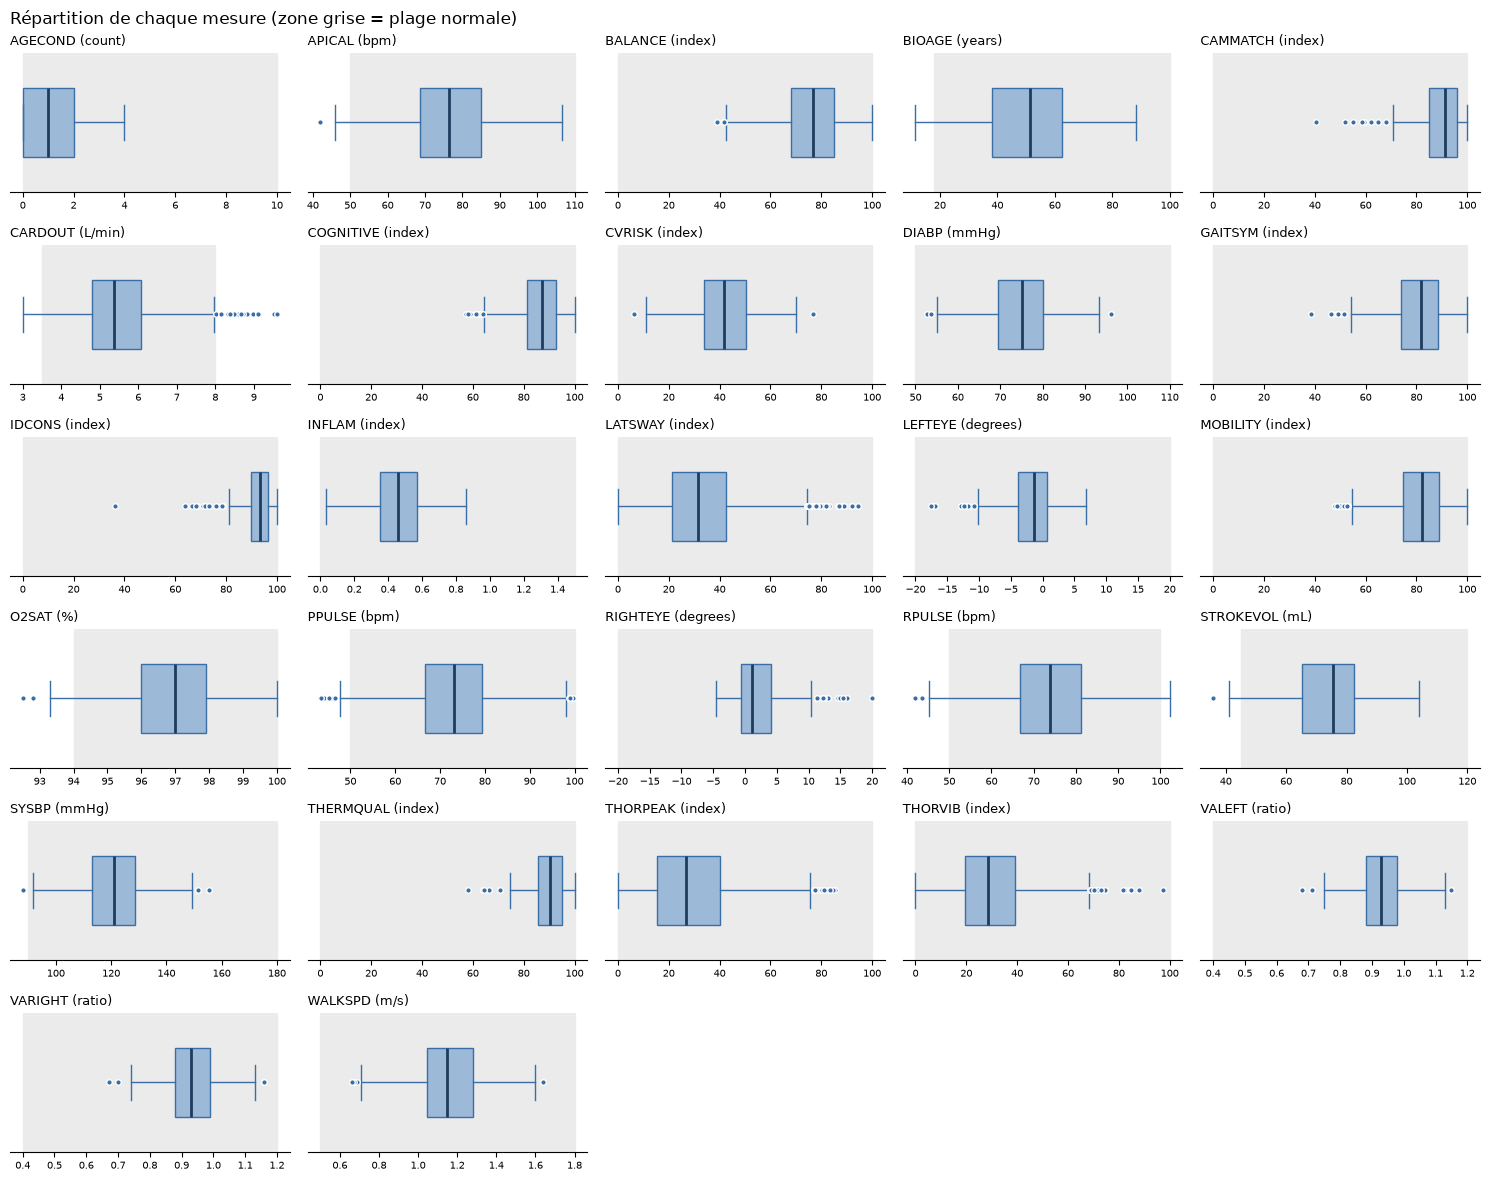

In [12]:
codes = catalogue.loc[catalogue["type"] == "nombre", "observation_code"].tolist()
fig, axes = plt.subplots(6, 5, figsize=(15, 12))
for ax, c in zip(axes.flat, codes):
    ref = catalogue.set_index("observation_code").loc[c]
    ax.axvspan(ref["plage_min"], ref["plage_max"], color="#ebebeb", zorder=0)
    ax.boxplot(o.loc[o["observation_code"] == c, "numeric_value"].dropna(), orientation="horizontal", widths=.5,
               patch_artist=True, boxprops=dict(facecolor="#9db9d8", edgecolor="#3b6ea5"),
               medianprops=dict(color="#1d3c5e", linewidth=2), whiskerprops=dict(color="#3b6ea5"),
               capprops=dict(color="#3b6ea5"), flierprops=dict(marker="o", markersize=4, markerfacecolor="#3b6ea5", markeredgecolor="white"))
    ax.set_title(f"{c} ({ref['unite']})", fontsize=9, loc="left")
    ax.set_yticks([]); ax.tick_params(labelsize=7)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
for ax in list(axes.flat)[len(codes):]:
    ax.axis("off")
fig.suptitle("Répartition de chaque mesure (zone grise = plage normale)", x=.01, ha="left")
plt.tight_layout(); plt.show()

On garde toutes ces valeurs, pour trois raisons. Aucune n'est impossible. Toutes les mesures sont de qualité « acceptable ». Et les mesures qui sortent le plus souvent de la norme sont précisément celles que les notes des médecins décrivent comme bizarres : un pouls différent selon l'endroit où on le prend (`APICAL` / `PPULSE`), un second battement dans la poitrine (`THORPEAK`, `THORVIB`), une démarche qui tangue (`LATSWAY`), un âge biologique sous 18 ans chez des adultes (`BIOAGE`). Les effacer reviendrait à effacer ce qu'on cherche.

Les graphiques montrent aussi que beaucoup de scores sont bloqués à 100, et certains pouls bloqués à 42. Ces valeurs plafonnées faussent un peu les moyennes et les corrélations linéaires, ce qu'il faudra garder en tête dans l'analyse.

## 8. Vérification finale de la cohérence entre les fichiers

On vérifie que chaque identifiant cité dans un fichier existe bien dans le fichier de référence, qu'une mesure, un acte ou une note concerne le même patient que sa consultation, et que les dates se suivent dans le bon ordre.

In [13]:
P, E = df["patient_administration"], df["clinical_encounters"].set_index("encounter_number")
O, CR, N = df["clinical_observations"], df["cardiac_recordings"], df["clinical_notes"]
controles = {}
for t in ["clinical_observations", "clinical_procedures", "cardiac_recordings", "clinical_notes"]:
    d = df[t]
    controles[f"{t} : consultation inconnue"] = (~d["encounter_number"].isin(E.index)).sum()
    controles[f"{t} : patient différent de celui de la consultation"] = (d["patient_number"] != d["encounter_number"].map(E["patient_number"])).sum()
controles["consultation : patient inconnu"] = (~E["patient_number"].isin(P["patient_number"])).sum()
controles["signal : enregistrement inconnu"] = (~df["cardiac_signal_samples"]["recording_id"].isin(CR["recording_id"])).sum()
controles["mesure prise hors du créneau de la consultation"] = ((O["observation_time"] < O["encounter_number"].map(E["encounter_start"])) |
                                                                (O["observation_time"] > O["encounter_number"].map(E["encounter_end"]))).sum()
controles["enregistrement cardiaque pas le jour de la consultation"] = (CR["recording_date"] != CR["encounter_number"].map(E["encounter_start"]).dt.normalize()).sum()
display(pd.Series(controles, name="problèmes").to_frame())

ecart = (N["document_date"] - N["encounter_number"].map(E["encounter_start"]).dt.normalize()).dt.days
print(f"Écart entre une note et sa consultation : de {ecart.min()} à {ecart.max()} jours ; {(ecart < 0).sum()} notes sur 30 datées AVANT")

,problèmes
clinical_observations : consultation inconnue,0
clinical_observations : patient différent de celui de la consultation,0
clinical_procedures : consultation inconnue,0
clinical_procedures : patient différent de celui de la consultation,0
cardiac_recordings : consultation inconnue,0
cardiac_recordings : patient différent de celui de la consultation,0
clinical_notes : consultation inconnue,0
clinical_notes : patient différent de celui de la consultation,0
consultation : patient inconnu,0
signal : enregistrement inconnu,0


Écart entre une note et sa consultation : de -1249 à 2670 jours ; 8 notes sur 30 datées AVANT


Tous les contrôles sont bons, à une exception près : **les dates des notes ne correspondent pas à celles de leur consultation**. L'écart va de 3 ans avant à 7 ans après, et 8 notes sont datées avant la consultation à laquelle elles sont rattachées. On ne corrige rien, mais dans l'analyse il ne faudra pas supposer qu'une note a été écrite le jour de la consultation. Un cas sort du lot : la seule patiente décédée (`PAT-31099`), vue pour la dernière fois en 2018, a un compte rendu d'imagerie daté de décembre 2023. Ce point sera à confronter aux autres dossiers lors de la mise en commun.

## 9. Export et bilan

Pour l'analyse, on prépare aussi un tableau avec une ligne par consultation et une colonne par type de mesure (`observations_wide`).

In [14]:
O = df["clinical_observations"]
assert not O.duplicated(subset=["encounter_number", "observation_code"]).any()
valeur = O["numeric_value"].astype(object).where(O["numeric_value"].notna(), O["text_value"])
large = O.assign(valeur=valeur).pivot(index="encounter_number", columns="observation_code", values="valeur")
large[codes] = large[codes].astype(float)
large = df["clinical_encounters"][["encounter_number", "patient_number", "encounter_start", "encounter_type"]].merge(
    large.reset_index(), on="encounter_number", how="left")

sorties = {**df, "observation_catalog": catalogue, "procedure_catalog": catalogue_actes,
           "observations_wide": large, "journal_nettoyage": pd.DataFrame(journal)}
for nom, d in sorties.items():
    d.to_csv(OUT / f"{nom}.csv", index=False, date_format="%Y-%m-%dT%H:%M:%S")

apres = etat_des_lieux(df)
pd.concat({"avant": avant, "après": apres}, axis=1)

avant                                                                                après                                                                              
                       lignes doublons manquants écrits en texte espaces en trop dates hors format standard lignes doublons manquants écrits en texte espaces en trop dates hors format standard
patient_administration    241        1                         0               3                          2    240        0                         0               0                          0
clinical_encounters      1069        2                         3               3                         10   1067        0                         0               0                          0
clinical_observations   17736        2                        55              50                          0  17734        0                         0               0                          0
clinical_procedures       311        1                         1               1                          3    310        0                         0               0                          0
cardiac_recordings         44        0                         0               0                          0     44        0                         0               0                          0
cardiac_signal_samples  96925        0                         0               0                          0  96925        0                         0               0                          0
clinical_notes             30        0                         0               0                          0     30        0                         0               0                          0

**Ce qui a été corrigé :** 6 doublons supprimés, des espaces et des majuscules uniformisés, une seule façon d'écrire une valeur manquante, des dates toutes au même format, environ 340 nombres réparés, et des colonnes inutiles retirées ou rangées dans des catalogues. Le détail se trouve dans `journal_nettoyage.csv`.

**Ce qui a été gardé exprès :** les valeurs manquantes qui ont une explication, toutes les valeurs extrêmes (marquées par `hors_plage_ref` et `outlier_iqr`) et le style d'écriture des professions.

**Pistes pour l'analyse :**
1. l'acte `MRP-42` et le matériel administré ;
2. le groupe des 53 patients à intitulé détaillé (dirigeants et enquêteurs) ;
3. les mesures bizarres (`APICAL`, `THORPEAK`, `LATSWAY`, `BIOAGE`, `IDCONS`) : sont-elles concentrées chez certains patients ?
4. le 20 juin 2025, où 22 consultations ont lieu le même jour, dont 17 avec des mesures prises exactement aux mêmes instants ;
5. la consultation isolée de 2026 et la note de 2023 concernant la patiente décédée.